# Cold-streak test: does a cold stretch predict the next three? (2025-26)

**Definitions fixed before looking at results.**

- Unit: one three-point attempt, 2025-26 regular season and playoffs, in time order within a game.
- *Team cold-streak measure:* the shooting team's 3P% over its previous **N** three-point attempts in the same game, for **N = 8, 10, 15**. The first N threes of each team-game are dropped (no full window).
- *Cold* = prior 3P% <= 25%. *Hot* = prior 3P% >= 50%. Everything between is the reference group. These cut-offs (about 10 points below / 14 above the league's 36%) are fixed here and not tuned.
- *Outcome:* whether the next three goes in.
- *Controls:* shooter fixed effects (who is shooting matters most), shot distance, zone (corner / above the break / other), the team's score margin before the shot (capped at +-20), home flag. Standard errors clustered by game.
- *Primary estimate:* linear probability model with the continuous prior 3P%. A negative-streak effect would mean a positive coefficient (cold predicts a miss).

Why no game fixed effects: with a within-game window, adding game fixed effects builds in a mechanical negative bias (the known streak-selection problem), so they are left out. Shooter fixed effects are across games and do not have that problem.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from src.features import load_threes_with_zone
plt.rcParams['figure.dpi'] = 110
t = load_threes_with_zone()
t['TG'] = t.GAME_ID + '_' + t.TEAM_ID.astype(str)
print(f'{len(t):,} threes, {t.TG.nunique()} team-games; overall 3P% {t.MADE.mean():.3f}')
t.groupby('ZONE').MADE.agg(['mean', 'size']).round(3)

96,813 threes, 2630 team-games; overall 3P% 0.359


,mean,size
ZONE,,
above_break,0.349,71625
corner,0.386,25146
other,0.524,42


In [2]:
t['M'] = t.MARGIN_BEFORE.clip(-20, 20) / 10
t['DIST'] = t.SHOT_DISTANCE
t['corner'] = (t.ZONE == 'corner').astype(int)
t['other'] = (t.ZONE == 'other').astype(int)
Ns = [8, 10, 15]
for N in Ns:
    t[f'prior{N}'] = t.groupby('TG').MADE.transform(lambda x: x.shift(1).rolling(N).mean())

def within(df, cols, by):
    return df[cols] - df.groupby(by)[cols].transform('mean')

def run(N, binary=False):
    d = t.dropna(subset=[f'prior{N}']).copy()
    d['cold'] = (d[f'prior{N}'] <= 0.25).astype(int)
    d['hot'] = (d[f'prior{N}'] >= 0.50).astype(int)
    d['prior'] = d[f'prior{N}']
    xs = ['cold', 'hot'] if binary else ['prior']
    cols = ['MADE'] + xs + ['DIST', 'corner', 'other', 'M', 'HOME']
    w = within(d, cols, 'PLAYER_ID')
    m = smf.ols('MADE ~ ' + ' + '.join(xs + ['DIST', 'corner', 'other', 'M', 'HOME']) + ' - 1', data=w).fit(
        cov_type='cluster', cov_kwds={'groups': d.GAME_ID})
    return d, m

rows = []
for N in Ns:
    d, m = run(N)
    ci = m.conf_int().loc['prior']
    rows.append(dict(N=N, shots=len(d), coef_per_10pts=m.params['prior'] / 10, ci_lo=ci[0] / 10, ci_hi=ci[1] / 10, p=m.pvalues['prior']))
cont = pd.DataFrame(rows).set_index('N')
print('Effect of +10 points of prior 3P% (in the team\'s last N threes) on the next three\'s make probability, in percentage points = coef x 100')
(cont[['coef_per_10pts', 'ci_lo', 'ci_hi']] * 100).round(3).join(cont[['shots', 'p']]).round(3)

Effect of +10 points of prior 3P% (in the team's last N threes) on the next three's make probability, in percentage points = coef x 100


,coef_per_10pts,ci_lo,ci_hi,shots,p
N,,,,,
8,-0.182,-0.388,0.024,75773,0.083
10,-0.154,-0.390,0.083,70513,0.204
15,-0.275,-0.600,0.051,57364,0.098


n_shots  raw_3pct  adj_effect_pp  ci_lo  ci_hi      p
N  group                                                              
8  cold            30235     0.354         -0.402 -1.247  0.444  0.352
   hot             23936     0.349         -1.460 -2.325 -0.596  0.001
   middle (ref)    21602     0.361            NaN    NaN    NaN    NaN
10 cold            16729     0.353         -0.146 -1.049  0.756  0.750
   hot             18990     0.352         -0.894 -1.755 -0.033  0.042
   middle (ref)    34794     0.357            NaN    NaN    NaN    NaN
15 cold             8731     0.352         -0.091 -1.203  1.020  0.872
   hot              7501     0.353         -0.863 -2.012  0.286  0.141
   middle (ref)    41132     0.357            NaN    NaN    NaN    NaN

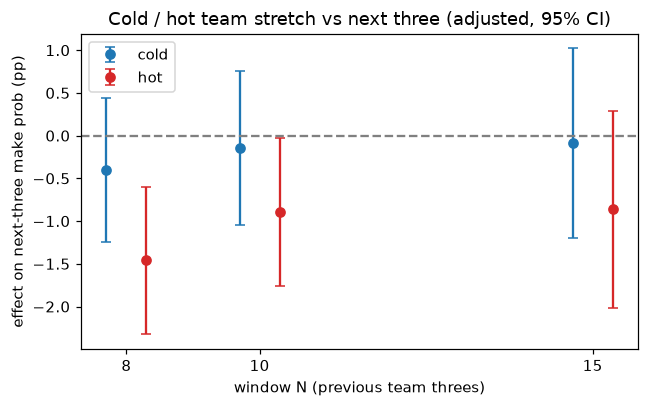

In [3]:
rows = []
for N in Ns:
    d, m = run(N, binary=True)
    ci = m.conf_int()
    for k in ['cold', 'hot']:
        rows.append(dict(N=N, group=k, n_shots=int(d[k].sum()), raw_3pct=d.loc[d[k] == 1, 'MADE'].mean(),
                         adj_effect_pp=m.params[k] * 100, ci_lo=ci.loc[k, 0] * 100, ci_hi=ci.loc[k, 1] * 100, p=m.pvalues[k]))
    rows.append(dict(N=N, group='middle (ref)', n_shots=int(((d.cold == 0) & (d.hot == 0)).sum()),
                     raw_3pct=d.loc[(d.cold == 0) & (d.hot == 0), 'MADE'].mean()))
bt = pd.DataFrame(rows).set_index(['N', 'group']); display(bt.round(3))
sub = bt.drop(index='middle (ref)', level='group').reset_index()
fig, ax = plt.subplots(figsize=(6, 3.8))
for i, (k, c) in enumerate([('cold', 'tab:blue'), ('hot', 'tab:red')]):
    r = sub[sub.group == k]
    ax.errorbar(r.N + (i - .5) * .6, r.adj_effect_pp, yerr=[r.adj_effect_pp - r.ci_lo, r.ci_hi - r.adj_effect_pp], fmt='o', c=c, capsize=3, label=k)
ax.axhline(0, c='gray', ls='--'); ax.set_xticks(Ns); ax.set_xlabel('window N (previous team threes)')
ax.set_ylabel('effect on next-three make prob (pp)'); ax.set_title('Cold / hot team stretch vs next three (adjusted, 95% CI)'); ax.legend(); plt.tight_layout(); plt.show()

## Robustness (specified in advance)

- **Raw vs adjusted:** the raw 3P% after a cold stretch above, against the adjusted effect, shows how much shooter identity and shot quality matter.
- **Late-game fouling / garbage time:** repeat excluding the final 5 minutes of regulation.

In [4]:
d, m = run(10)
d2 = d[d.SEC_ELAPSED < 2880 - 300].copy()
cols = ['MADE', 'prior', 'DIST', 'corner', 'other', 'M', 'HOME']
w = within(d2, cols, 'PLAYER_ID')
m2 = smf.ols('MADE ~ prior + DIST + corner + other + M + HOME - 1', data=w).fit(cov_type='cluster', cov_kwds={'groups': d2.GAME_ID})
ci = m2.conf_int().loc['prior'] / 10 * 100
print(f"N=10, excluding last 5 min: +10 pts prior 3P% -> {m2.params['prior']*10:+.2f} pp (95% CI {ci[0]:+.2f} to {ci[1]:+.2f}), p={m2.pvalues['prior']:.3f}")
# no shooter FE, no controls: the naive number
naive = smf.ols('MADE ~ prior', data=d).fit(cov_type='cluster', cov_kwds={'groups': d.GAME_ID})
print(f"N=10 naive (no controls): +10 pts prior 3P% -> {naive.params['prior']*10:+.2f} pp, p={naive.pvalues['prior']:.3f}")

N=10, excluding last 5 min: +10 pts prior 3P% -> -0.14 pp (95% CI -0.41 to +0.12), p=0.282
N=10 naive (no controls): +10 pts prior 3P% -> -0.00 pp, p=0.977


## Is the 'hot' result real, or a finite-sequence artifact?

Looking at what follows a high-makes window inside a short, fixed-length sequence is biased toward misses even for a shooter with no streaks at all (the selection problem noted above: a hot window has already used up some of the makes in a game's sequence). To size that bias, we **shuffle the make/miss outcomes within each team-game** (which destroys any streaks but keeps each game's number of makes) and recompute the raw gap between the next three after a hot (or cold) window and after a middle window. If the actual gap sits inside the shuffled range, there is no streak effect beyond the artifact.

In [5]:
tt = t.reset_index(drop=True)
codes = pd.factorize(tt.TG)[0]
order = np.lexsort((np.arange(len(tt)), codes))          # group by TG, keep time order inside
made0 = tt.MADE.values[order].astype(float); c0 = codes[order]
start = np.r_[0, np.flatnonzero(np.diff(c0)) + 1]; sizes = np.diff(np.r_[start, len(c0)])
pos = np.arange(len(c0)) - np.repeat(start, sizes)

def gaps(made, N):
    cs = np.r_[0, np.cumsum(made)]
    idx = np.arange(len(made))
    prior = (cs[idx] - cs[np.maximum(idx - N, 0)]) / N
    ok = pos >= N
    cold, hot = ok & (prior <= .25), ok & (prior >= .5)
    mid = ok & ~cold & ~hot
    return made[cold].mean() - made[mid].mean(), made[hot].mean() - made[mid].mean()

rng = np.random.default_rng(1)
rows = []
for N in Ns:
    act = gaps(made0, N); null = []
    for _ in range(300):
        shuf = made0[np.lexsort((rng.random(len(c0)), c0))]       # shuffle within each team-game
        null.append(gaps(shuf, N))
    null = np.array(null)
    for j, k in enumerate(['cold', 'hot']):
        rows.append(dict(N=N, group=k, actual_gap_pp=act[j] * 100, shuffled_mean_pp=null[:, j].mean() * 100,
                         shuffled_2_5=np.percentile(null[:, j], 2.5) * 100, shuffled_97_5=np.percentile(null[:, j], 97.5) * 100,
                         excess_pp=(act[j] - null[:, j].mean()) * 100))
perm = pd.DataFrame(rows).set_index(['N', 'group']); perm.round(2)

actual_gap_pp  shuffled_mean_pp  shuffled_2_5  shuffled_97_5  \
N  group                                                                 
8  cold           -0.65              0.14         -0.67           0.99   
   hot            -1.24             -0.16         -1.04           0.68   
10 cold           -0.41              0.10         -0.82           0.98   
   hot            -0.53             -0.25         -1.04           0.48   
15 cold           -0.48              0.16         -0.62           1.07   
   hot            -0.40             -0.31         -1.34           0.83   

          excess_pp  
N  group             
8  cold       -0.79  
   hot        -1.08  
10 cold       -0.51  
   hot        -0.28  
15 cold       -0.64  
   hot        -0.09

## Spurs Game 4 pattern: hot first half, cold second half

In the 2026 Finals Game 4 the Spurs shot 14-of-26 from three in the first half and 3-of-17 in the second. Is a split like that more common across 2025-26 than shooting luck would produce?

Fixed in advance: team-games with **at least 8 threes in each half**; *hot-then-cold* = first half 3P% >= 50% and second half <= 25%. Chance baseline: each three goes in with the shooter's season 3P% (shrunk toward the league 36% with 50 pseudo-attempts), simulated 5,000 times. We also compare how first-half and second-half results correlate in the actual data against the same simulated null.

In [6]:
shr = t.groupby('PLAYER_ID').MADE.agg(['sum', 'size'])
shr['p'] = (shr['sum'] + 0.36 * 50) / (shr['size'] + 50)
t['P_EXP'] = t.PLAYER_ID.map(shr.p)
t['H2'] = (t.SEC_ELAPSED >= 1440).astype(int)
a = t.groupby(['TG', 'H2']).agg(n=('MADE', 'size'), made=('MADE', 'sum'), exp=('P_EXP', 'sum')).unstack('H2')
a = a[(a['n'] >= 8).all(axis=1)]
n1, n2 = a['n'][0].values, a['n'][1].values
pct1, pct2 = a['made'][0].values / n1, a['made'][1].values / n2
hotcold = ((pct1 >= .5) & (pct2 <= .25))
coldhot = ((pct1 <= .25) & (pct2 >= .5))
print(f'{len(a)} team-games with 8+ threes per half')
rng = np.random.default_rng(0)
# simulate with per-shot probabilities
tt = t[t.TG.isin(a.index)].sort_values(['TG', 'H2']).reset_index(drop=True)
grp = tt.groupby(['TG', 'H2'], sort=True).ngroup().values
G = grp.max() + 1
cnt = np.zeros(2, dtype=float); corr_sim = []
hc_sim, ch_sim = [], []
P = tt.P_EXP.values
nn = np.bincount(grp, minlength=G)
for _ in range(5000):
    mk = np.bincount(grp, weights=(rng.random(len(P)) < P), minlength=G).reshape(-1, 2)
    nm = nn.reshape(-1, 2)
    p1s, p2s = mk[:, 0] / nm[:, 0], mk[:, 1] / nm[:, 1]
    hc_sim.append(((p1s >= .5) & (p2s <= .25)).sum()); ch_sim.append(((p1s <= .25) & (p2s >= .5)).sum())
    corr_sim.append(np.corrcoef(p1s, p2s)[0, 1])
hc_sim, ch_sim, corr_sim = map(np.array, (hc_sim, ch_sim, corr_sim))
act_corr = np.corrcoef(pct1, pct2)[0, 1]
out = pd.DataFrame({'actual': [hotcold.sum(), coldhot.sum(), act_corr],
                    'simulated_mean': [hc_sim.mean(), ch_sim.mean(), corr_sim.mean()],
                    'sim_95pct_range': [f'{np.percentile(hc_sim,2.5):.0f}-{np.percentile(hc_sim,97.5):.0f}', f'{np.percentile(ch_sim,2.5):.0f}-{np.percentile(ch_sim,97.5):.0f}',
                                        f'{np.percentile(corr_sim,2.5):.3f} to {np.percentile(corr_sim,97.5):.3f}'],
                    'p_actual_or_more_extreme': [(hc_sim >= hotcold.sum()).mean(), (ch_sim >= coldhot.sum()).mean(), 2 * min((corr_sim <= act_corr).mean(), (corr_sim >= act_corr).mean())]},
                   index=['hot-then-cold games', 'cold-then-hot games', 'corr(H1 3P%, H2 3P%)'])
out

2611 team-games with 8+ threes per half


,actual,simulated_mean,sim_95pct_range,p_actual_or_more_extreme
hot-then-cold games,73.000000,67.021200,52-83,0.2388
cold-then-hot games,68.000000,67.330400,52-83,0.4822
"corr(H1 3P%, H2 3P%)",-0.003026,0.011129,-0.027 to 0.049,0.4616


In [7]:
# Also show the Spurs Game 4 itself and the most extreme actual hot-then-cold games
pr = pd.DataFrame({'H1_made': a['made'][0], 'H1_n': n1, 'H2_made': a['made'][1], 'H2_n': n2, 'H1_pct': pct1, 'H2_pct': pct2})
pr['gap'] = pr.H1_pct - pr.H2_pct
print('Largest first-half-minus-second-half 3P% gaps:'); display(pr.sort_values('gap', ascending=False).head(5).round(2))
print('Game-level spread of the gap: actual sd %.3f' % pr.gap.std())

Largest first-half-minus-second-half 3P% gaps:


,H1_made,H1_n,H2_made,H2_n,H1_pct,H2_pct,gap
TG,,,,,,,
0022500403_1610612754,12,20,1,20,0.60,0.05,0.55
0022500186_1610612741,10,14,3,15,0.71,0.20,0.51
0022500897_1610612749,11,19,2,20,0.58,0.10,0.48
0022500052_1610612740,7,15,0,12,0.47,0.00,0.47
0022501153_1610612762,9,17,1,15,0.53,0.07,0.46


Game-level spread of the gap: actual sd 0.161


## Reading the results

- **Cold stretches do not predict the next three.** After a cold window (prior 3P% <= 25%) the next three goes in at 35.2-35.4% against 35.7-36.1% for the middle group, and the adjusted effect is -0.1 to -0.4 points (95% CIs roughly -1.2 to +1.0, p = 0.35 to 0.87), for N = 8, 10 and 15. The continuous version is -0.15 to -0.28 points per +10 points of prior 3P%, not significant. The naive no-controls version is 0.00.
- **No 'hot hand' either.** After a hot window the next three is slightly *less* likely to go in (adjusted -0.9 to -1.5 points, significant at N = 8 and N = 10, not at N = 15). That is the opposite of momentum. The within-game shuffle shows the sign is partly the finite-sequence artifact (shuffled gaps average -0.2 to -0.3 points), so the true excess is about -1 point at N = 8 and near zero at N = 10 and 15.
- **Late-game fouling does not drive it:** excluding the final five minutes leaves the estimate unchanged (-0.14 points per +10, CI -0.41 to +0.12).
- **Spurs-pattern splits are what luck produces.** 73 hot-first-half/cold-second-half team-games against about 67 expected by chance (simulated 95% range 52-83, p = 0.24). The reverse pattern: 68 against 67. First-half and second-half 3P% are uncorrelated (r = -0.003 against a chance mean of +0.011). The most extreme game (0022500403, 12-of-20 then 1-of-20) is the kind of outlier expected among 2,600 team-games.
- **Bottom line:** a null result. Being cold, over a window of 8 to 15 threes, does not make the next three worse by more than about one point, once shooter, distance, zone and score margin are controlled. Limits: only one season, team-level windows (not the shooter's own streaks), and no defender or openness data.